**IMPORT THE LIBRARIES**

In [3]:
# ***--------------------------------------------------------------***
# 1. IMPORT LIBRARIES
# ***--------------------------------------------------------------***

import pandas as pd  # Data manipulation
import numpy as np  # Numerical operations
import seaborn as sns  # Advanced visualization
import matplotlib.pyplot as plt  # Plotting
from sklearn.preprocessing import LabelEncoder, StandardScaler  # Encoding and scaling
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV  # Model evaluation
from sklearn.ensemble import RandomForestClassifier  # Random Forest
from sklearn.tree import DecisionTreeClassifier  # Decision Tree
from xgboost import XGBClassifier  # XGBoost
from sklearn.linear_model import LogisticRegression  # Logistic Regression
from imblearn.over_sampling import RandomOverSampler  # Handle class imbalance
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score, accuracy_score, roc_auc_score  # Metrics

import warnings
warnings.filterwarnings("ignore")  # Ignore warnings


**LOADING THE DATASET**

In [7]:
# ***--------------------------------------------------------------***
# 2. LOAD DATASET
# ***--------------------------------------------------------------***

df = pd.read_excel(r'C:\Users\USER\Desktop\main_projects\hr attrtion\hr attrition.xlsx')  # Load Excel dataset
df.head()  # Display first 5 rows
print(df.info())  # Check column types and non-null counts
print(df.shape)  # Shape of dataset


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

**CHECKING FOR DUPLICATES AND NULL VALUES**

In [8]:
# ***--------------------------------------------------------------***
# 3. DATA CLEANING: DUPLICATES & NULLS
# ***--------------------------------------------------------------***

df.duplicated().sum()  # Check for duplicates
df.isna().sum()  # Check for missing values
df.columns  # List of columns


Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

**DESCRIPTIVE STATISTICS OF THE OBJECT COLUMN**

In [9]:
# ***--------------------------------------------------------------***
# 4. DESCRIPTIVE STATISTICS
# ***--------------------------------------------------------------***

df.describe(include='object').T  # Summary of categorical/object columns


,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


**VALUE COUNTS AND PLOTS OF CATEGORICAL COLUMNS**

Attrition
No     1233
Yes     237
Name: count, dtype: int64


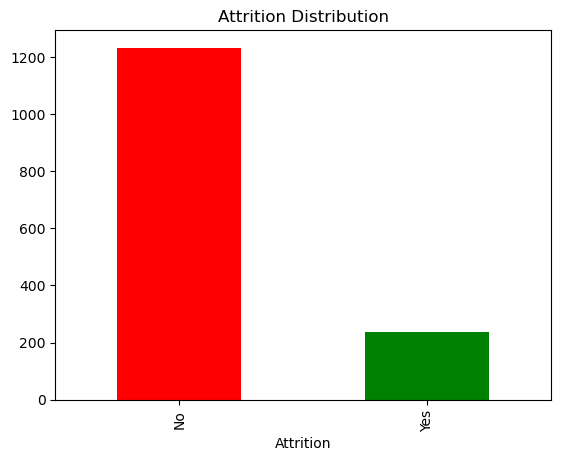

In [ ]:
# Attrition distribution
print(df['Attrition'].value_counts())
df['Attrition'].value_counts().plot(kind='bar', color=['red', 'green'], title='Attrition Distribution')
plt.show()


**VALUE COUNT OF THE BUSINESS TRAVEL COLUMN**

BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64


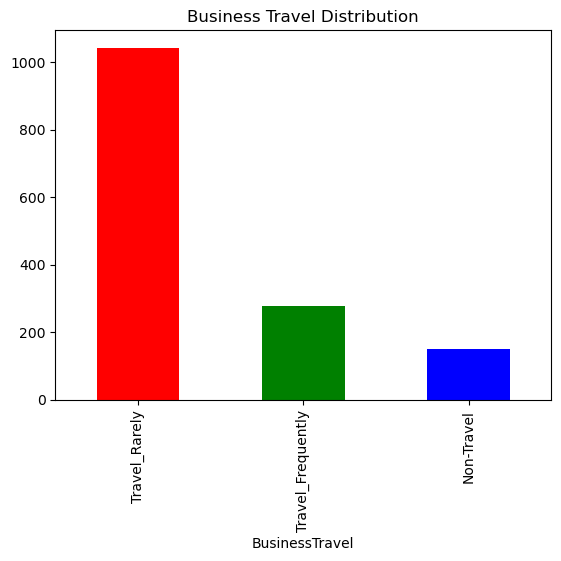

In [11]:
# Business Travel distribution
print(df['BusinessTravel'].value_counts())
df['BusinessTravel'].value_counts().plot(kind='bar', color=['red', 'green', 'blue'], title='Business Travel Distribution')
plt.show()


**VALUE COUNT OF THE DEPARTMENT COLUMN**

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64


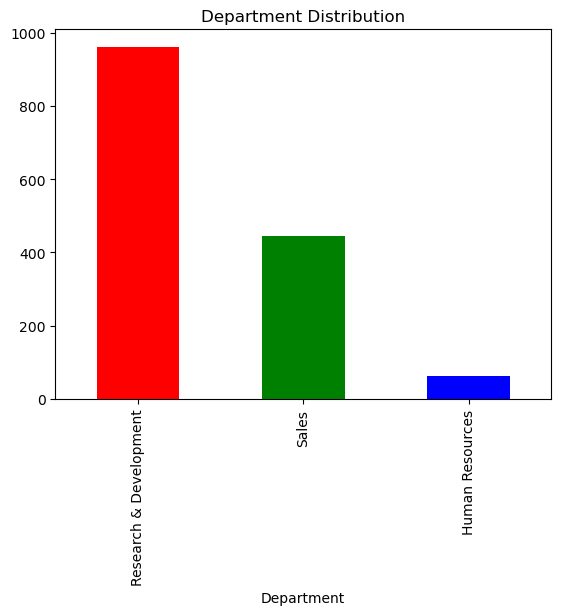

In [12]:
# Department distribution
print(df['Department'].value_counts())
df['Department'].value_counts().plot(kind='bar', color=['red', 'green', 'blue'], title='Department Distribution')
plt.show()


**VALUE COUNT OF THE EDUCATION COLUMN**

Education
3    572
4    398
2    282
1    170
5     48
Name: count, dtype: int64


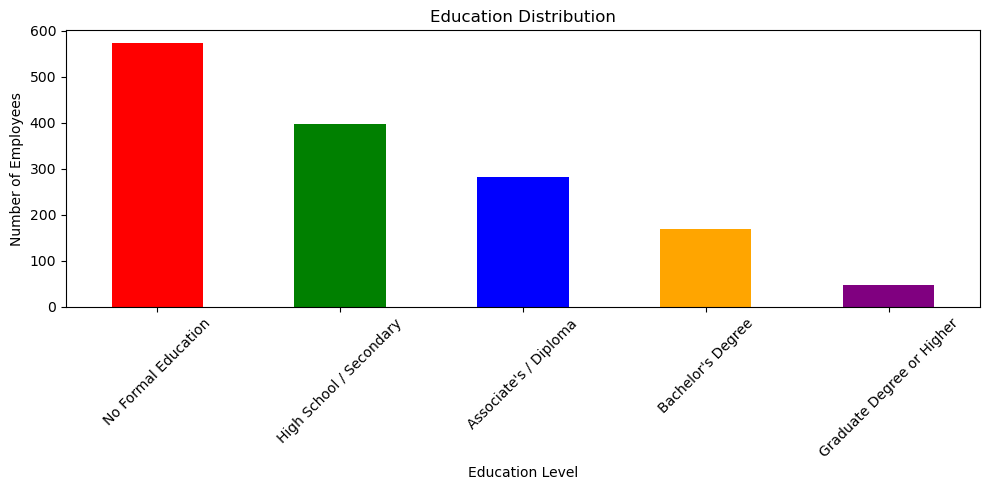

In [ ]:
# Education distribution
print(df['Education'].value_counts())
df['Education'].value_counts().plot(
    kind='bar',
    title='Education Distribution',
    color=['red', 'green', 'blue', 'orange', 'purple'],
    figsize=(10, 5)
)
plt.xticks(
    ticks=[0, 1, 2, 3, 4],
    labels=["No Formal Education", "High School / Secondary", "Associate's / Diploma", "Bachelor's Degree", "Graduate Degree or Higher"],
    rotation=45
)
plt.xlabel('Education Level')
plt.ylabel('Number of Employees')
plt.tight_layout()
plt.show()


**VALUE COUNT OF EDUCATION FIELD**

EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64


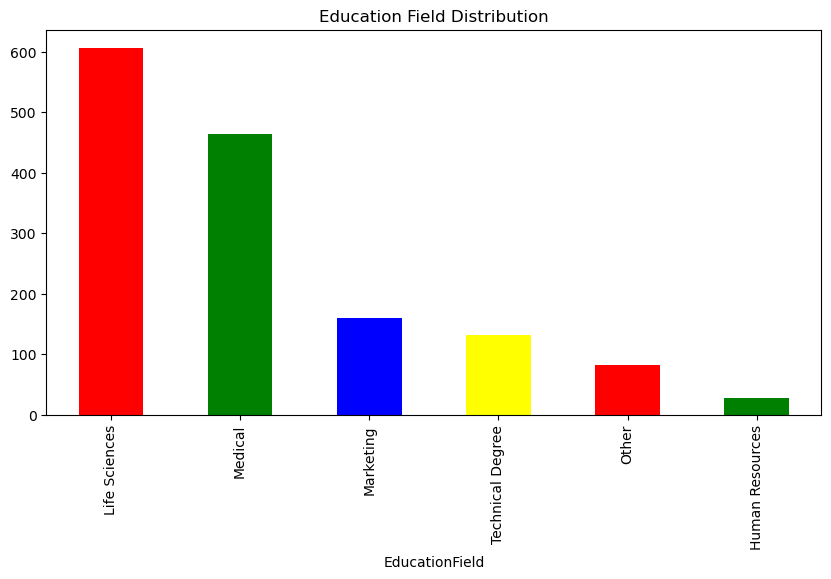

In [ ]:
print(df['EducationField'].value_counts())  # Education Field distribution
df['EducationField'].value_counts().plot(kind='bar', color = ['red', 'green', 'blue', 'yellow'], title='Education Field Distribution',figsize=(10, 5))
plt.show()


**VALUE COUNT OF GENDER**

Gender
Male      882
Female    588
Name: count, dtype: int64


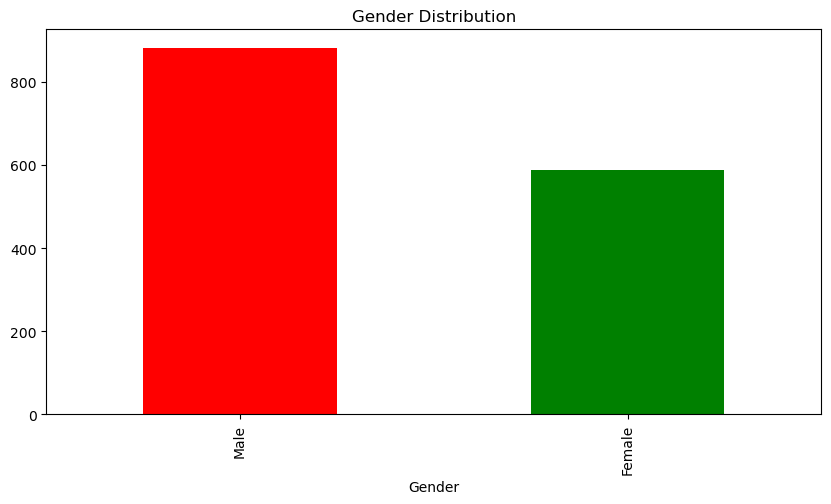

In [ ]:
print(df['Gender'].value_counts())  # Gender
df['Gender'].value_counts().plot(kind='bar', color = ['red', 'green'],title='Gender Distribution', figsize=(10, 5))
plt.show()


**VALUE COUNT OF JOB ROLE**

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64


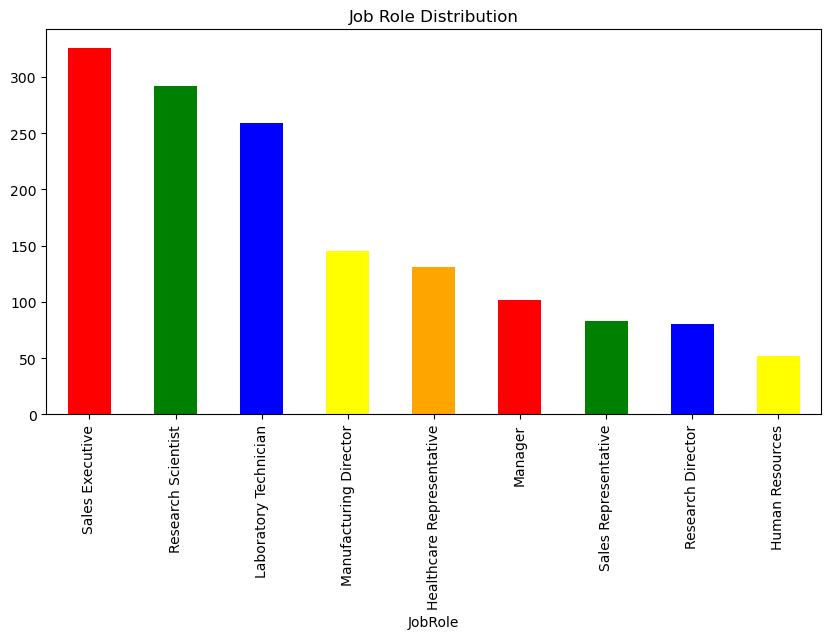

In [ ]:
print(df['JobRole'].value_counts()) # Job Role distribution
df['JobRole'].value_counts().plot(kind='bar', color = ['red', 'green', 'blue', 'yellow', 'orange'], title='Job Role Distribution', figsize=(10, 5))
plt.show()


**VALUE COUNT OF MARITAL STATUS**

MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64


<Axes: title={'center': 'Marital Status Distribution'}, xlabel='MaritalStatus'>

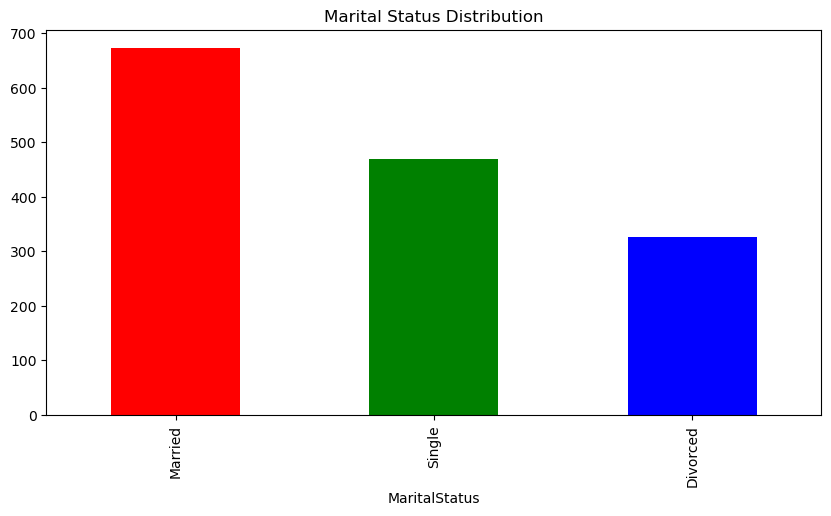

In [17]:
print(df['MaritalStatus'].value_counts())  # Marital Status distribution
df['MaritalStatus'].value_counts().plot(kind='bar', color = ['red', 'green', 'blue'], title='Marital Status Distribution', figsize=(10, 5))


**CORRELATION MATRIX OF COLUMNS**

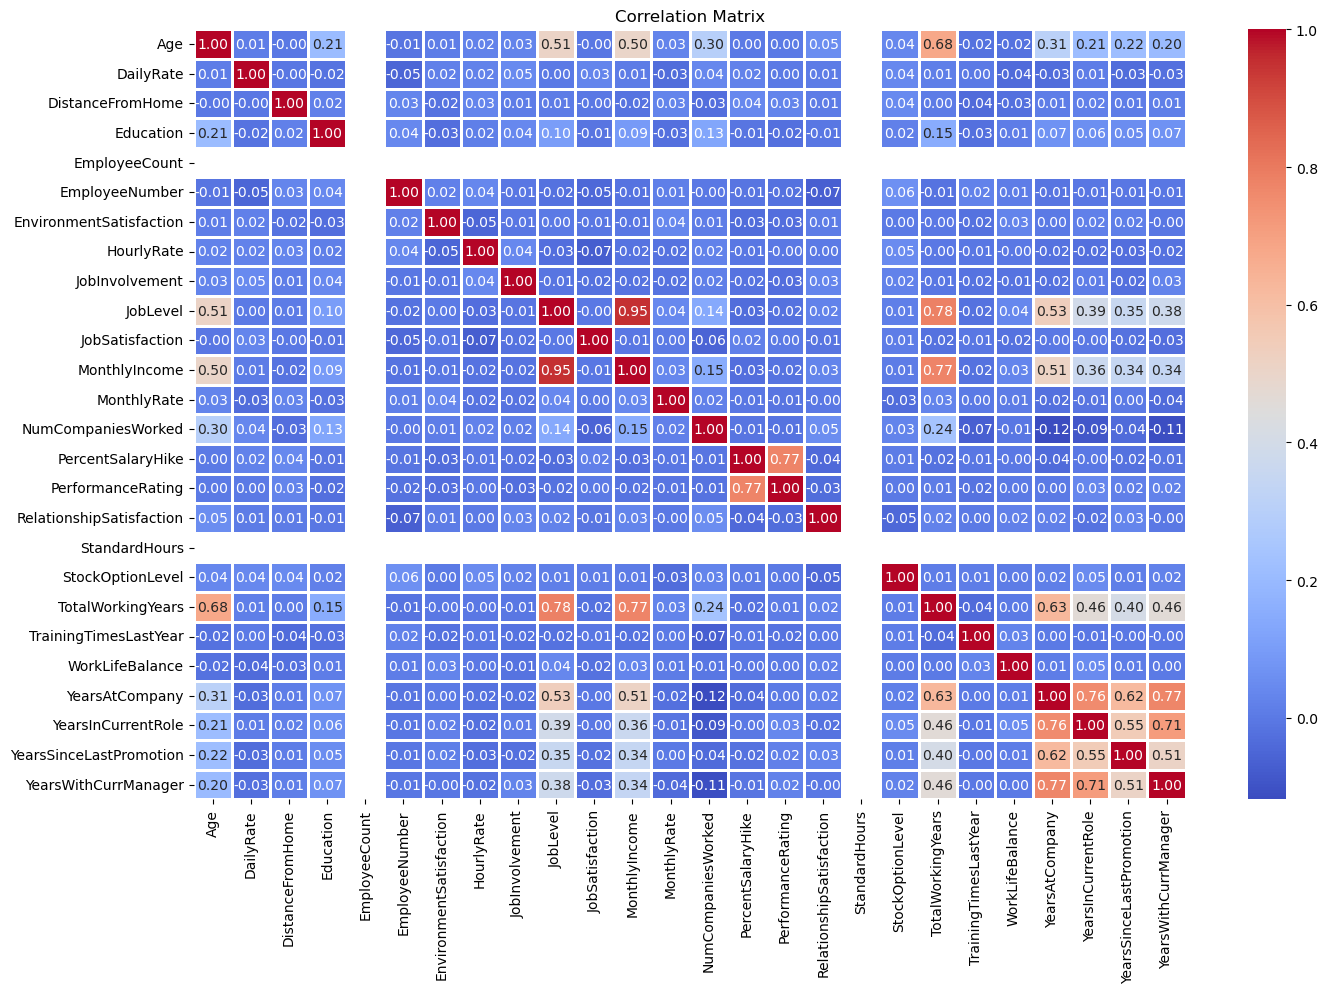

In [18]:
correlation = df.select_dtypes(include=['int64', 'float64']).corr()    # Correlation matrix for numerical features
plt.figure(figsize=(16, 10))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap='coolwarm', lw  =1)
plt.title('Correlation Matrix')
plt.show()


**ENCODING CATEGORICAL COLUMNS**

In [ ]:
# ***--------------------------------------------------------------***
# 7. ENCODING CATEGORICAL VARIABLES
# ***--------------------------------------------------------------***

# Drop irrelevant columns
df = df.drop(['EmployeeNumber','StandardHours','Over18','EmployeeCount'], axis=1)

# Encode categorical variables
label_encoders = {}
for col in df.select_dtypes(include='object').columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
df.head()  # Display first 5 rows after encoding


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,2,1102,2,1,2,1,2,0,...,3,1,0,8,0,1,6,4,0,5
1,49,0,1,279,1,8,1,1,3,1,...,4,4,1,10,3,3,10,7,1,7
2,37,1,2,1373,1,2,2,4,4,1,...,3,2,0,7,3,3,0,0,0,0
3,33,0,1,1392,1,3,4,1,4,0,...,3,3,0,8,3,3,8,7,3,0
4,27,0,2,591,1,2,1,3,1,1,...,3,4,1,6,3,3,2,2,2,2


**HANDLING CLASS IMBALANCE**

In [21]:
# ***--------------------------------------------------------------***
# 8. HANDLE CLASS IMBALANCE WITH OVERSAMPLING
# ***--------------------------------------------------------------***

X = df.drop('Attrition', axis=1)
y = df['Attrition']

oversampler = RandomOverSampler(random_state=42)
X_resampled, y_resampled = oversampler.fit_resample(X, y)

print("Original class distribution:", X.shape)
print("Resampled class distribution:", X_resampled.shape)


Original class distribution: (1470, 30)
Resampled class distribution: (2466, 30)


**SPLITTING AND FITTING THE MODEL USINF RANDOM FOREST CLASSSIFIER**

In [22]:
# ***--------------------------------------------------------------***
# 9. SPLIT DATA INTO TRAIN AND TEST
# ***--------------------------------------------------------------***

X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)


(1972, 30) (494, 30) (1972,) (494,)


**FITTING THE MODEL USING XGBCLASSIFIER**


Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.65      0.66       250
           1       0.65      0.67      0.66       244

    accuracy                           0.66       494
   macro avg       0.66      0.66      0.66       494
weighted avg       0.66      0.66      0.66       494



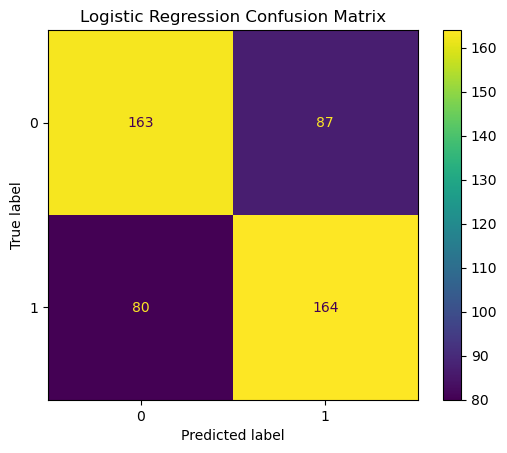


Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90       250
           1       0.85      0.99      0.91       244

    accuracy                           0.90       494
   macro avg       0.92      0.91      0.90       494
weighted avg       0.92      0.90      0.90       494



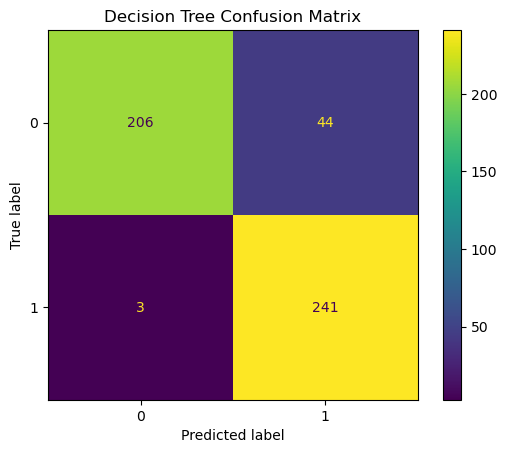


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.94      0.95       250
           1       0.94      0.97      0.95       244

    accuracy                           0.95       494
   macro avg       0.95      0.95      0.95       494
weighted avg       0.95      0.95      0.95       494



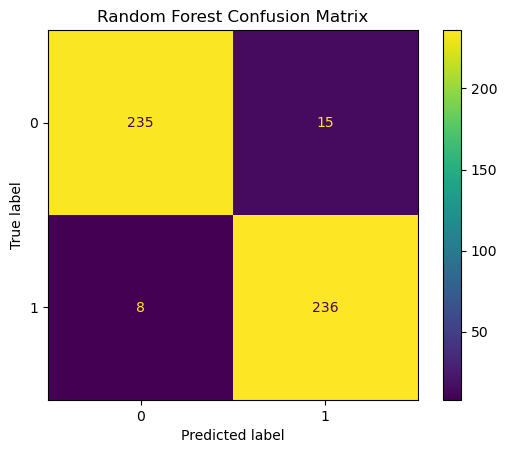


XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.94      0.96       250
           1       0.94      0.98      0.96       244

    accuracy                           0.96       494
   macro avg       0.96      0.96      0.96       494
weighted avg       0.96      0.96      0.96       494



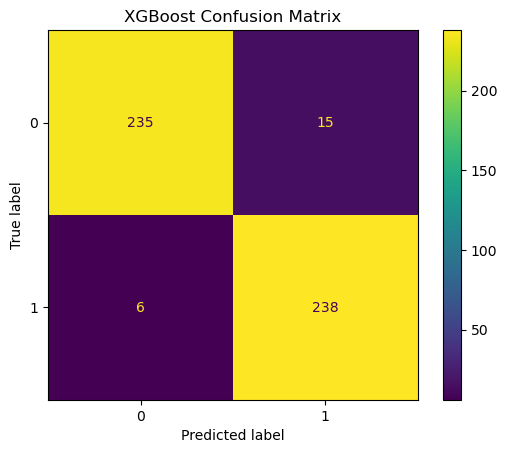

In [23]:
# ***--------------------------------------------------------------***
# 10. FIT MODELS AND EVALUATE
# ***--------------------------------------------------------------***

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='logloss')
}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"\n{model_name} Classification Report:")
    print(classification_report(y_test, y_pred))
    
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.title(f'{model_name} Confusion Matrix')
    plt.show()


**FINAL MODEL**

XGBoost Train Accuracy: 1.0000
XGBoost Test Accuracy: 0.9575

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.94      0.96       250
           1       0.94      0.98      0.96       244

    accuracy                           0.96       494
   macro avg       0.96      0.96      0.96       494
weighted avg       0.96      0.96      0.96       494

XGBoost ROC AUC: 0.9890


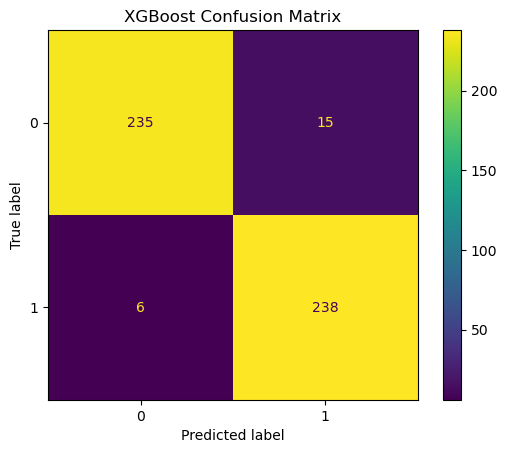

In [25]:
# ***--------------------------------------------------------------***
# 11. FINAL XGBOOST MODEL TRAINING AND SAVE
# ***--------------------------------------------------------------***

xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

# Evaluation
y_pred = xgb_model.predict(X_test)
probs = xgb_model.predict_proba(X_test)[:,1]
train_accuracy = xgb_model.score(X_train, y_train)
test_accuracy = xgb_model.score(X_test, y_test)
roc = roc_auc_score(y_test, probs)

print(f'XGBoost Train Accuracy: {train_accuracy:.4f}')
print(f'XGBoost Test Accuracy: {test_accuracy:.4f}')
print("\nXGBoost Classification Report:")
print(classification_report(y_test, y_pred))
print(f"XGBoost ROC AUC: {roc:.4f}")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('XGBoost Confusion Matrix')
plt.show()


**SAVE THE MODEL**

In [ ]:
# Save model and encoders
import pickle
with open('xgb_model.pkl', 'wb') as f:
    pickle.dump(xgb_model, f)

with open('label_encoders.pkl', 'wb') as f:
    pickle.dump(label_encoders, f)
